# Assignment 1

## Extract webpage data given the url

Create a Python script that performs basic web scraping on a page to extract all the information into text and returns it as a string. String should not contain tags.

In [ ]:
import requests
from bs4 import BeautifulSoup


def parse_web_page(url):
    """
    Fetch the content of the given web page.

    Args:
        url (str): The URL of the web page to fetch.

    Returns:
        str: The content of the page as a string.

    Raises:
        HTTPError: If the HTTP request returned an unsuccessful status code.
    """
    response = requests.get(url, headers={"User-Agent": "anything really"}, timeout=30)
    response.raise_for_status()
    soup = BeautifulSoup(response.content, "html.parser")
    for tag in soup(["script", "style", "noscript", "template"]):
        tag.decompose()
    return soup.get_text(separator="\n", strip=True)

print(parse_web_page('https://fmi.chnu.edu.ua/')[:255])
print(parse_web_page('https://en.wikipedia.org/wiki/Web_scraping')[:255])

Головна - Факультет математики та інформатики
Перейти до основного вмісту
clg-math@chnu.edu.ua
58012, Україна, м. Чернівці, вул. Університетська, 28
Новини
Всі
Загальні
Оголошення
Події
Студенту
Викладачу
Вітання
Діяльність
Наукова
Конференції
Семінари
Ас
Web scraping - Wikipedia
Jump to content
Main menu
Main menu
move to sidebar
hide
Navigation
Main page
Contents
Current events
Random article
About Wikipedia
Contact us
Contribute
Help
Learn to edit
Community portal
Recent changes
Upload file
Special page


## Get data from the API

Create a python script that performs basic request to API endpoint and saves that data to a JSON file result.json.

In [11]:
import json


def parse_api(api_url):
    """
    Fetch the data of the given API endpoint and save it to result.json.

    Args:
        api_url (str): The URL of the API endpoint.

    Returns:
        None.

    Raises:
        HTTPError: If the HTTP request returned an unsuccessful status code.
    """
    response = requests.get(api_url, timeout=30)
    response.raise_for_status()
    with open("result.json", "w", encoding="utf-8") as file:
        json.dump(response.json(), file, ensure_ascii=False, indent=4)

parse_api('https://api.github.com/')

## Parse the json file

Parse the `weather.json` file and return weather data for a specific date, that is given as a parameter. Return the data as an array.

In [ ]:
import re
from datetime import datetime, timezone

DATE_PATTERN = re.compile(r"(\d{4})-(\d{1,2})-(\d{1,2})")
DATE_KEY_HINTS = ("date", "time", "dt")


def split_date(date):
    match = DATE_PATTERN.search(date)
    if not match:
        raise ValueError(f"Date must look like YYYY-M-D, got: {date!r}")
    return tuple(int(part) for part in match.groups())


def to_ymd(value, key=""):
    if isinstance(value, str):
        match = DATE_PATTERN.search(value)
        return tuple(int(part) for part in match.groups()) if match else None
    is_number = isinstance(value, (int, float)) and not isinstance(value, bool)
    if is_number and value > 1e8 and any(hint in str(key).lower() for hint in DATE_KEY_HINTS):
        seconds = value / 1000 if value > 1e11 else value
        moment = datetime.fromtimestamp(seconds, tz=timezone.utc)
        return (moment.year, moment.month, moment.day)
    return None


def record_matches(record, target):
    scalars = {k: v for k, v in record.items() if not isinstance(v, (dict, list))}
    if any(to_ymd(v, k) == target for k, v in scalars.items()):
        return True
    lowered = {str(k).lower(): v for k, v in scalars.items()}
    if all(part in lowered for part in ("year", "month", "day")):
        try:
            return (int(lowered["year"]), int(lowered["month"]), int(lowered["day"])) == target
        except (TypeError, ValueError):
            return False
    return False


def _columnar_matches(node, target):
    columns = {
        k: v for k, v in node.items()
        if isinstance(v, list) and v and not any(isinstance(x, (dict, list)) for x in v)
    }
    for key, values in columns.items():
        positions = [i for i, x in enumerate(values) if to_ymd(x, key) == target]
        if positions:
            return [{k: v[i] for k, v in columns.items() if i < len(v)} for i in positions]
    return []


def find_records(node, target):
    found = []
    if isinstance(node, dict):
        if record_matches(node, target):
            return [node]
        columnar = _columnar_matches(node, target)
        if columnar:
            return columnar
        for key, value in node.items():
            if to_ymd(key) == target:
                found.extend(value if isinstance(value, list) else [value])
            else:
                found.extend(find_records(value, target))
    elif isinstance(node, list):
        for item in node:
            found.extend(find_records(item, target))
    return found


def parse_json(date):
    """
    Parse the data from weather.json file and return weather data for a given date.

    Args:
        date (str): The date for which we look up the weather.

    Returns:
        list: a list of weather data for a given date.
    """
    target = split_date(date)
    with open("resources/weather.json", encoding="utf-8") as file:
        data = json.load(file)
    return find_records(data, target)

target_date = '2024-8-19'
print(parse_json(target_date))

[{'date': '2024-08-19', 'max_temperature': 30.0, 'min_temperature': 21.0, 'precipitation': 5.0, 'wind_speed': 10.0, 'humidity': 70, 'weather_description': 'Light rain'}]


## Parse the csv file

Parse the `weather.csv` file and return weather data for a specific date, that is given as a parameter. Return the data as an array.

In [13]:
import pandas as pd


def csv_dates(df):
    for column in df.columns:
        if pd.api.types.is_numeric_dtype(df[column]):
            continue
        parts = df[column].astype(str).str.extract(DATE_PATTERN.pattern).astype(float)
        if parts.notna().all(axis=1).mean() > 0.9:
            return pd.to_datetime(
                pd.DataFrame({"year": parts[0], "month": parts[1], "day": parts[2]}),
                errors="coerce",
            )
    lowered = {str(c).lower().strip(): c for c in df.columns}
    if all(part in lowered for part in ("year", "month", "day")):
        return pd.to_datetime(
            pd.DataFrame({part: df[lowered[part]] for part in ("year", "month", "day")}),
            errors="coerce",
        )
    return None

def parse_csv(date):
    """
    Parse the data from weather.csv file and return weather data for a given date.

    Args:
        date (str): The date for which we look up the weather.

    Returns:
        list: a list of weather data for a given date.
    """
    year, month, day = split_date(date)
    df = pd.read_csv("resources/weather.csv")
    dates = csv_dates(df)
    if dates is None:
        raise ValueError("weather.csv has no recognizable date column")
    mask = (dates.dt.year == year) & (dates.dt.month == month) & (dates.dt.day == day)
    return df[mask].to_dict("records")

target_date = '1997-5-22'
print(parse_csv(target_date))

[{'CET': '1997-5-22', 'Max TemperatureC': 25.0, 'Mean TemperatureC': 18.0, 'Min TemperatureC': 10.0, 'Dew PointC': 11.0, 'MeanDew PointC': 8.0, 'Min DewpointC': 6.0, 'Max Humidity': 88.0, ' Mean Humidity': 54.0, ' Min Humidity': 34.0, ' Max Sea Level PressurehPa': 1017, ' Mean Sea Level PressurehPa': 1015, ' Min Sea Level PressurehPa': 1012, ' Max VisibilityKm': 10.0, ' Mean VisibilityKm': 10.0, ' Min VisibilitykM': 10.0, ' Max Wind SpeedKm/h': 11, ' Mean Wind SpeedKm/h': 3, ' Max Gust SpeedKm/h': nan, 'Precipitationmm': 0.0, ' CloudCover': 3.0, ' Events': nan, 'WindDirDegrees': 277}]


## Visualize data

Visualize the weather.csv data using matplotlib. Choose your own approach to data visualization. Save the results (as .png, .webp files etc., your choise) in this repository.

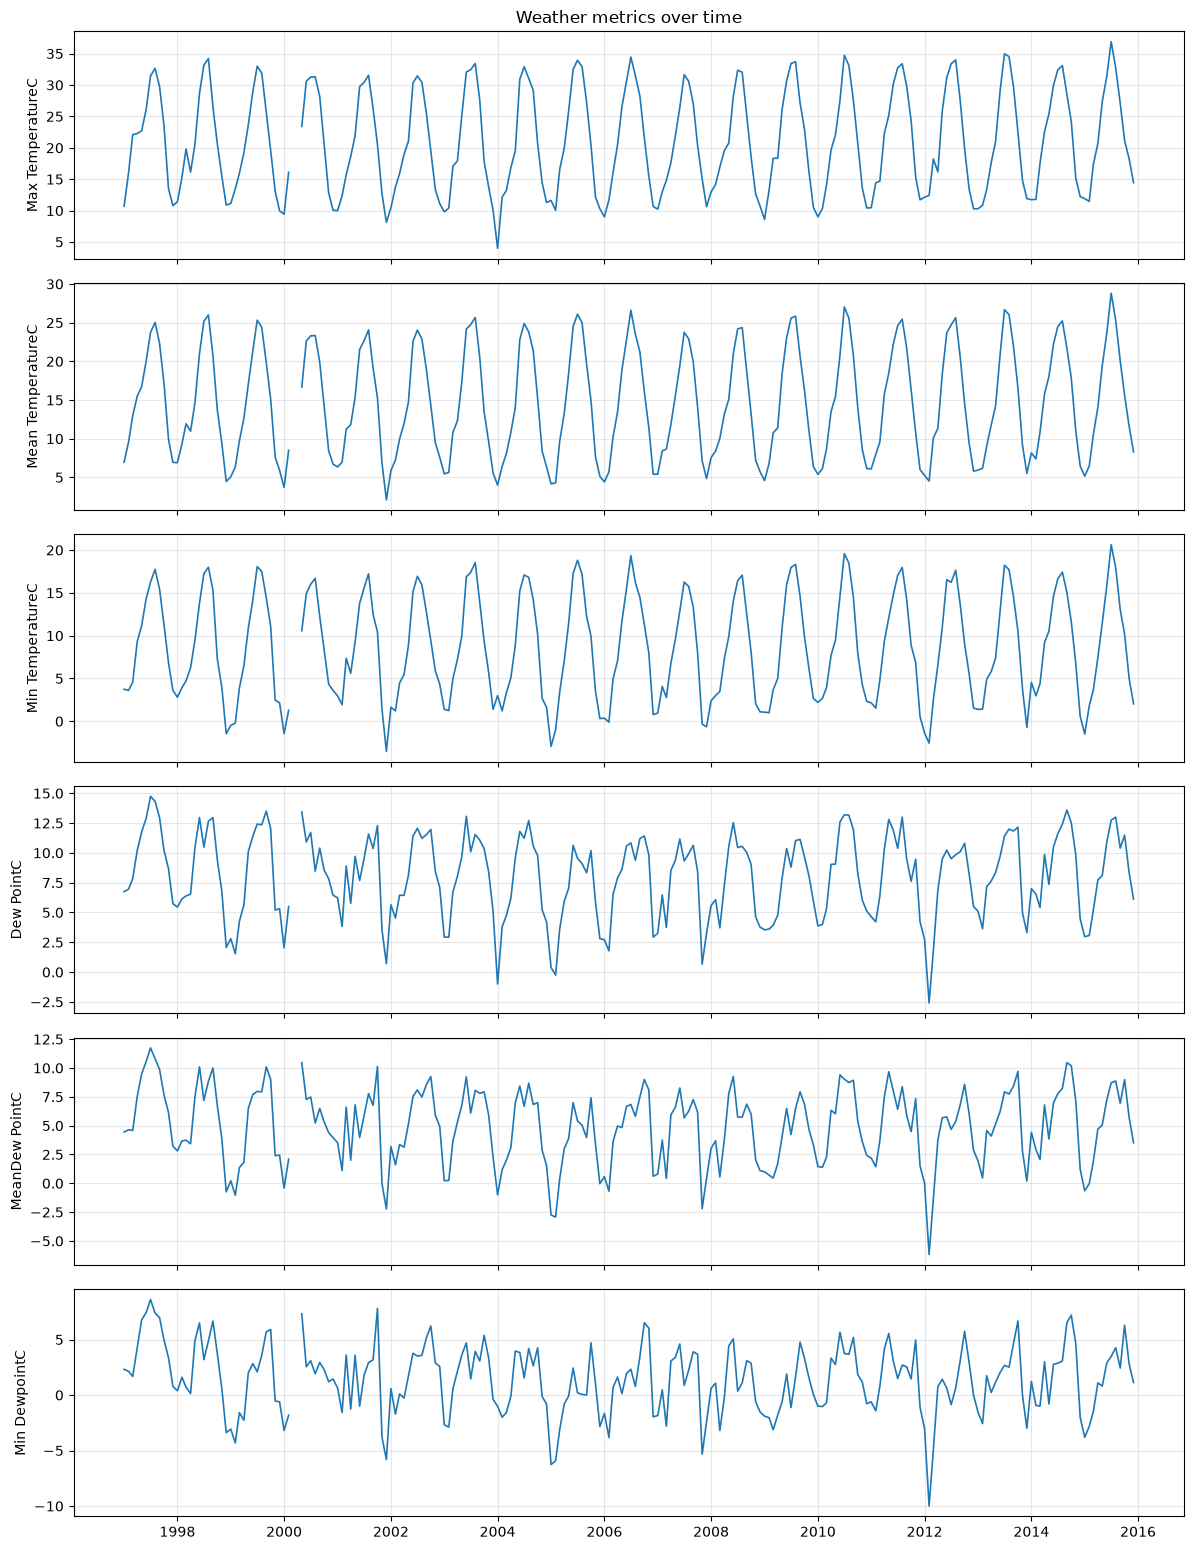

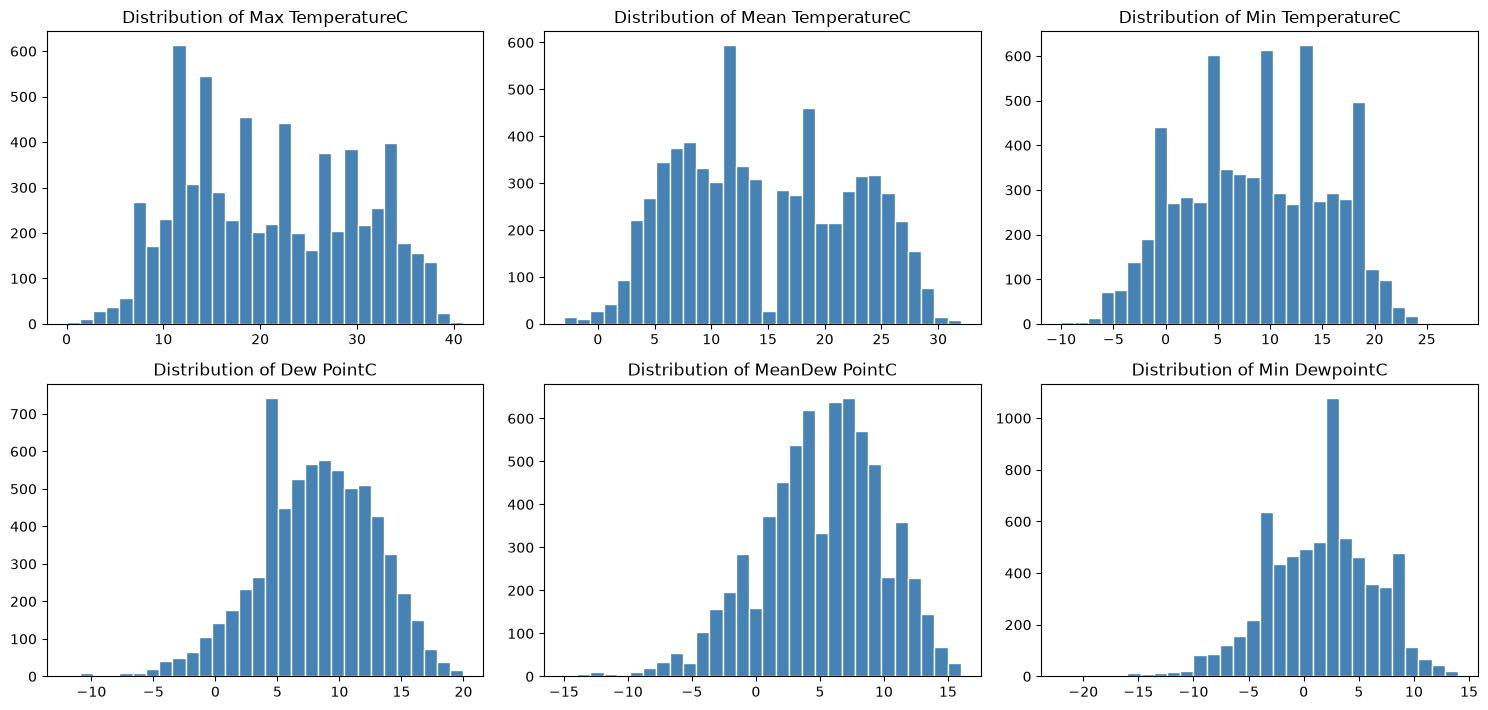

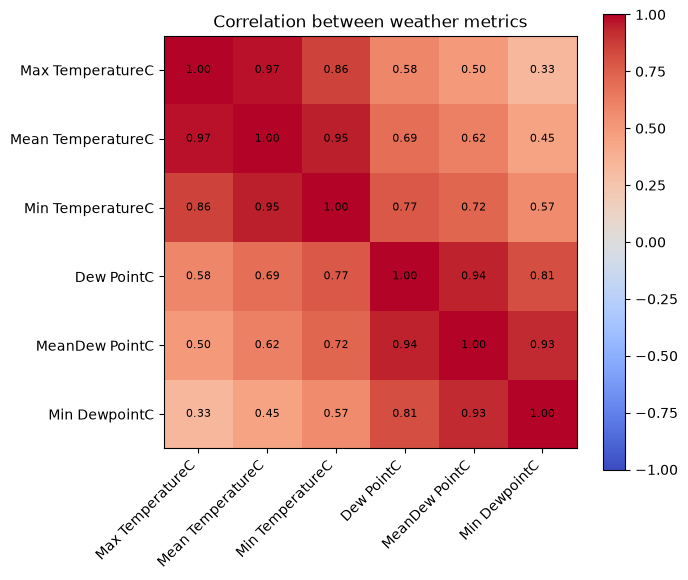

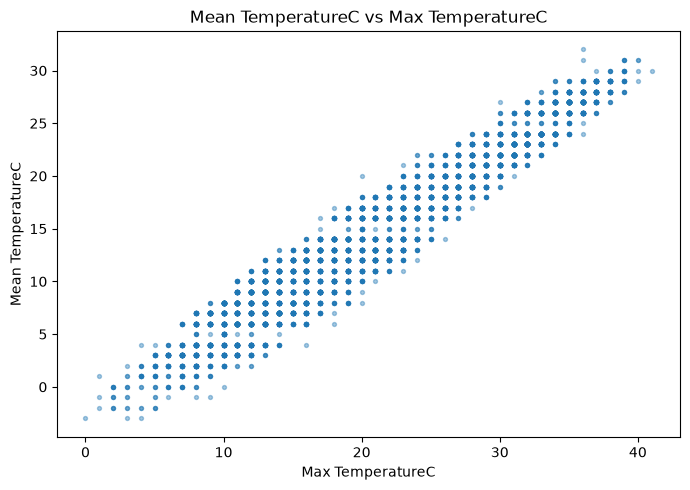

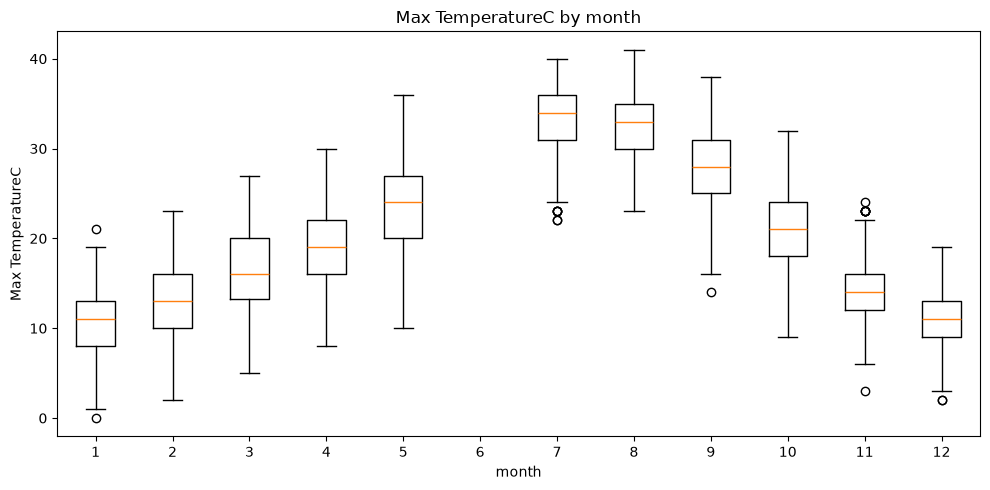

In [14]:
import matplotlib.pyplot as plt
import numpy as np


def visualize_data():
    """
    Parse the data from weather.csv file and visualize it using Matplotlib. Use more then one visualization. 
    Save the results in the repository.

    Args:
        None: None.

    Returns:
        None: None.
    """
    df = pd.read_csv("resources/weather.csv")
    dates = csv_dates(df)
    if dates is not None:
        df = df.assign(date=dates).dropna(subset=["date"]).sort_values("date")

    skip = {"year", "month", "day", "date"}
    numeric = [c for c in df.select_dtypes("number").columns if str(c).lower() not in skip][:6]
    if not numeric:
        raise ValueError("weather.csv has no numeric columns to visualize")

    if dates is not None:
        series = df.set_index("date")[numeric]
        if len(series) > 1500:
            series = series.resample("MS").mean()
        fig, axes = plt.subplots(len(numeric), 1, figsize=(12, 2.6 * len(numeric)), sharex=True)
        for ax, column in zip(np.atleast_1d(axes), numeric):
            ax.plot(series.index, series[column], linewidth=1.2)
            ax.set_ylabel(column)
            ax.grid(alpha=0.3)
        np.atleast_1d(axes)[0].set_title("Weather metrics over time")
        fig.tight_layout()
        fig.savefig("weather_timeseries.png", dpi=150)
        plt.show()

    cols = min(3, len(numeric))
    rows = int(np.ceil(len(numeric) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3.6 * rows))
    for ax, column in zip(np.atleast_1d(axes).ravel(), numeric):
        ax.hist(df[column].dropna(), bins=30, color="steelblue", edgecolor="white")
        ax.set_title(f"Distribution of {column}")
    for ax in np.atleast_1d(axes).ravel()[len(numeric):]:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig("weather_histograms.png", dpi=150)
    plt.show()

    if len(numeric) > 1:
        corr = df[numeric].corr()
        fig, ax = plt.subplots(figsize=(7, 6))
        image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
        ax.set_xticks(range(len(numeric)), numeric, rotation=45, ha="right")
        ax.set_yticks(range(len(numeric)), numeric)
        for i in range(len(numeric)):
            for j in range(len(numeric)):
                ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
        fig.colorbar(image)
        ax.set_title("Correlation between weather metrics")
        fig.tight_layout()
        fig.savefig("weather_correlation.png", dpi=150)
        plt.show()

        fig, ax = plt.subplots(figsize=(7, 5))
        ax.scatter(df[numeric[0]], df[numeric[1]], s=8, alpha=0.4)
        ax.set_xlabel(numeric[0])
        ax.set_ylabel(numeric[1])
        ax.set_title(f"{numeric[1]} vs {numeric[0]}")
        fig.tight_layout()
        fig.savefig("weather_scatter.png", dpi=150)
        plt.show()

    if dates is not None:
        monthly = df.assign(month=df["date"].dt.month).groupby("month")[numeric[0]].apply(list)
        fig, ax = plt.subplots(figsize=(10, 5))
        ax.boxplot(monthly.tolist(), tick_labels=monthly.index.tolist())
        ax.set_xlabel("month")
        ax.set_ylabel(numeric[0])
        ax.set_title(f"{numeric[0]} by month")
        fig.tight_layout()
        fig.savefig("weather_monthly_boxplot.png", dpi=150)
        plt.show()

visualize_data()

## Data imputation and normalization.

Download kaggle dataset with incomplete/missing data, and try data imputation techniques (mean, median, mode, knn) on that data. Normalize the data with best option for each dataset (minmax, z-score, robust). Visualize the data (choose your own approach to data visualization).

Dataset options:
- Different Types of Missing Data (by Suryaprabha19) https://www.kaggle.com/datasets/suryaprabha19/different-types-of-missing-data
- Retail Product Dataset with Missing Values (by Himel Sarder) https://www.kaggle.com/datasets/himelsarder/retail-product-dataset-with-missing-values
- Data Cleaning - Feature Imputation (by 
Mr.Machine) https://www.kaggle.com/datasets/ilayaraja07/data-cleaning-feature-imputation
- BI intro to data cleaning eda and machine learning (by Walekhwa Tambiti Leo Philip) https://www.kaggle.com/datasets/walekhwatlphilip/intro-to-data-cleaning-eda-and-machine-learning

Missing values before imputation:
lunch    25
dtype: int64
Missing values after imputation: 0
Outlier share=0.006, mean |skew|=0.28 -> using z-score scaling


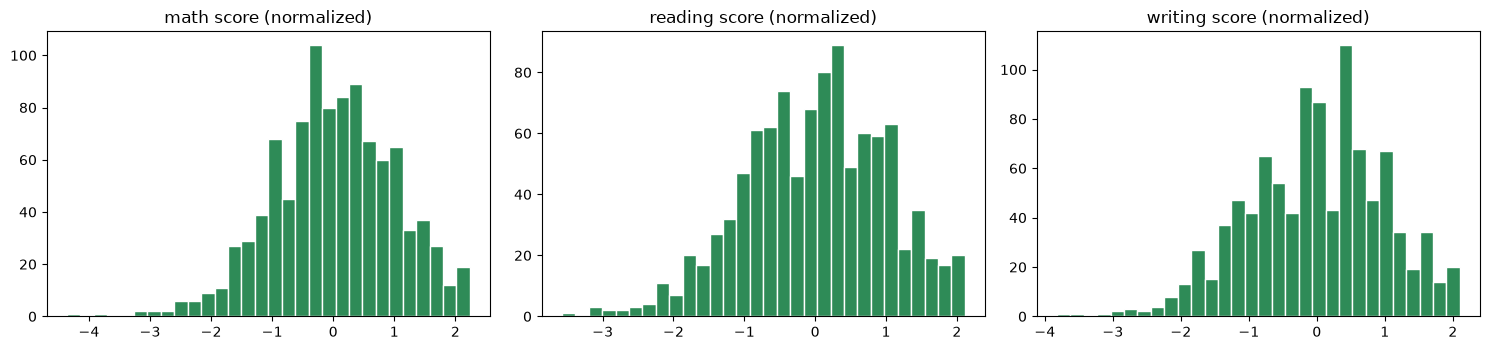

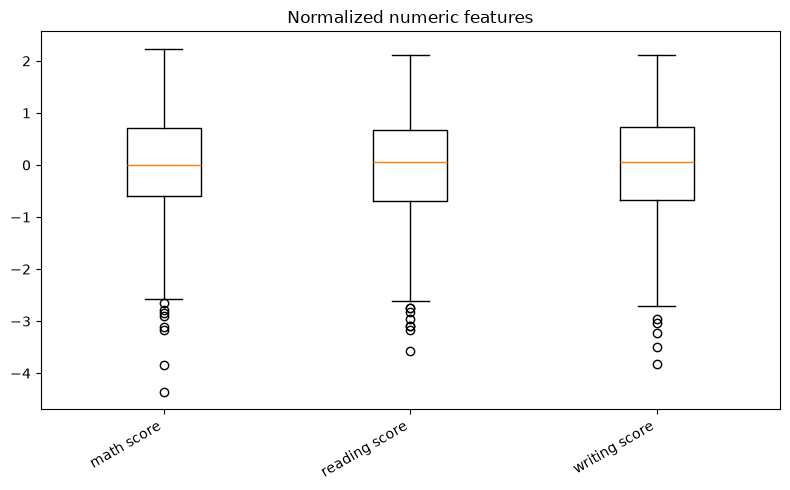

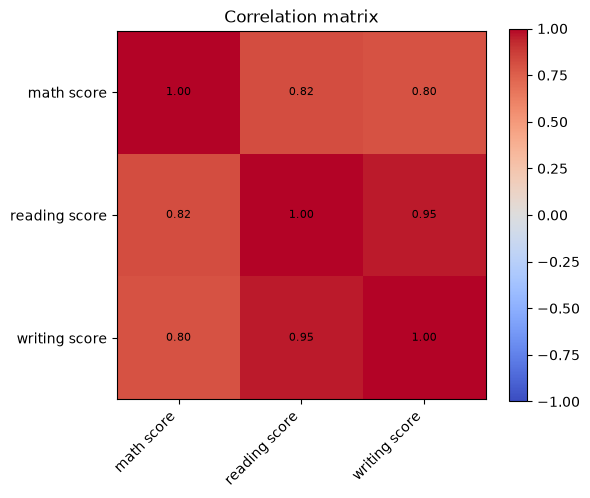

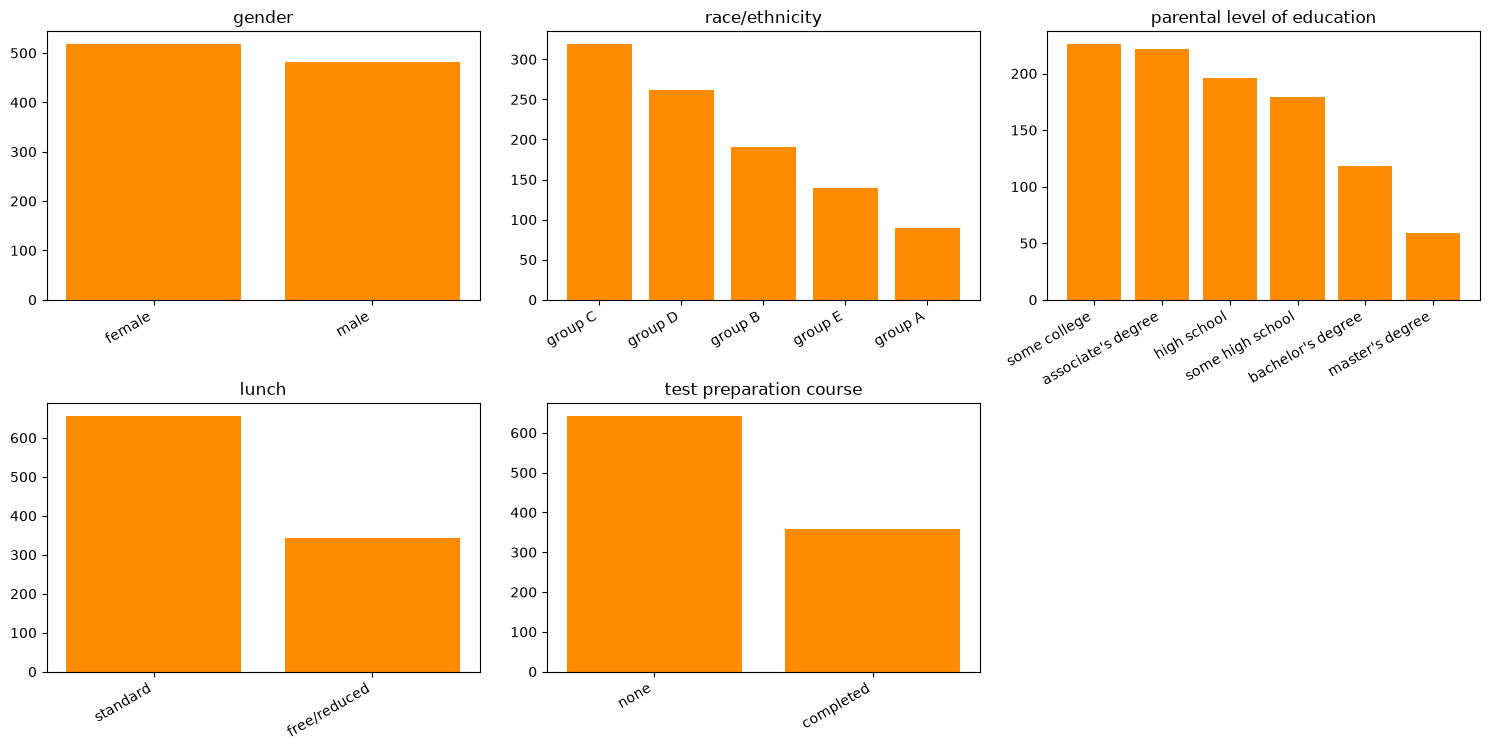

In [15]:
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from kagglehub import KaggleDatasetAdapter
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler


def load_dataset(url, csv_file):
    """
    Load the dataset from Kaggle using kagglehub.

    Args:
        url (str): The URL of the Kaggle dataset.
        csv_file (str): The name of the CSV file to load from the dataset.
    Returns:
        pd.DataFrame: The loaded dataset as a pandas DataFrame.
    """
    df = kagglehub.dataset_load(
            KaggleDatasetAdapter.PANDAS,
            url,
            csv_file
        )
    return df


def impute_numeric(frame, strategy):
    if strategy == "knn":
        scaler = MinMaxScaler()
        scaled = scaler.fit_transform(frame)
        filled = KNNImputer(n_neighbors=5).fit_transform(scaled)
        return pd.DataFrame(scaler.inverse_transform(filled), columns=frame.columns, index=frame.index)
    filled = SimpleImputer(strategy=strategy).fit_transform(frame)
    return pd.DataFrame(filled, columns=frame.columns, index=frame.index)


def score_numeric_strategies(frame, fraction=0.1, seed=42):
    complete = frame.dropna()
    if len(complete) < 30:
        return {}
    rng = np.random.default_rng(seed)
    hidden = rng.random(complete.shape) < fraction
    hidden[hidden.all(axis=1)] = False
    masked = frame.copy()
    masked.loc[complete.index] = complete.mask(hidden)
    scores = {}
    for strategy in ("mean", "median", "knn"):
        restored = impute_numeric(masked, strategy).loc[complete.index]
        errors = (restored.values - complete.values)[hidden] / np.tile(complete.std(ddof=0).replace(0, 1).values, (len(complete), 1))[hidden]
        scores[strategy] = float(np.sqrt(np.mean(errors ** 2)))
    return scores


def impute_data(df):
    """
    Parse the data from file and impute missing values using your preferred method.

    Args:
        df (pd.DataFrame): The dataset as a pandas DataFrame.

    Returns:
        pd.DataFrame: The dataset with imputed values.
    """
    df = df.copy()
    print("Missing values before imputation:")
    print(df.isna().sum()[df.isna().sum() > 0])

    numeric_cols = df.select_dtypes("number").columns.tolist()
    categorical_cols = [c for c in df.columns if c not in numeric_cols]

    for column in categorical_cols:
        if df[column].isna().any():
            df[column] = df[column].fillna(df[column].mode().iloc[0])

    usable = [c for c in numeric_cols if df[c].notna().any()]
    if usable and df[usable].isna().any().any():
        scores = score_numeric_strategies(df[usable])
        best = min(scores, key=scores.get) if scores else "knn"
        print(f"Numeric imputation RMSE (in std units): {scores} -> using {best}")
        df[usable] = impute_numeric(df[usable], best)

    print("Missing values after imputation:", int(df.isna().sum().sum()))
    return df


def normalize_data(df):
    """
    Normalize the data using your preferred method.

    Args:
        df (pd.DataFrame): The dataset as a pandas DataFrame.

    Returns:
        pd.DataFrame: The dataset with normalized values.
    """
    df = df.copy()
    numeric_cols = df.select_dtypes("number").columns.tolist()
    if not numeric_cols:
        return df

    q1 = df[numeric_cols].quantile(0.25)
    q3 = df[numeric_cols].quantile(0.75)
    iqr = q3 - q1
    outside = (df[numeric_cols] < q1 - 1.5 * iqr) | (df[numeric_cols] > q3 + 1.5 * iqr)
    outlier_share = float(outside.mean().mean())
    skewness = float(df[numeric_cols].skew().abs().mean())

    if outlier_share > 0.02:
        name, scaler = "robust", RobustScaler()
    elif skewness < 0.5:
        name, scaler = "z-score", StandardScaler()
    else:
        name, scaler = "minmax", MinMaxScaler()
    print(f"Outlier share={outlier_share:.3f}, mean |skew|={skewness:.2f} -> using {name} scaling")

    df[numeric_cols] = scaler.fit_transform(df[numeric_cols])
    return df


def visualize_data(df):
    """
    Visualize the data using Matplotlib. Use more then one visualization. 
    Save the results in the repository.

    Args:
        df (pd.DataFrame): The dataset as a pandas DataFrame.

    Returns:
        None: None.
    """
    numeric_cols = df.select_dtypes("number").columns.tolist()
    categorical_cols = [c for c in df.columns if c not in numeric_cols and df[c].nunique() <= 12]

    if numeric_cols:
        cols = min(3, len(numeric_cols))
        rows = int(np.ceil(len(numeric_cols) / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3.6 * rows))
        for ax, column in zip(np.atleast_1d(axes).ravel(), numeric_cols):
            ax.hist(df[column], bins=30, color="seagreen", edgecolor="white")
            ax.set_title(f"{column} (normalized)")
        for ax in np.atleast_1d(axes).ravel()[len(numeric_cols):]:
            ax.axis("off")
        fig.tight_layout()
        fig.savefig("imputed_histograms.png", dpi=150)
        plt.show()

        fig, ax = plt.subplots(figsize=(8, 5))
        ax.boxplot([df[c] for c in numeric_cols], tick_labels=numeric_cols)
        ax.set_title("Normalized numeric features")
        plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
        fig.tight_layout()
        fig.savefig("imputed_boxplot.png", dpi=150)
        plt.show()

    if len(numeric_cols) > 1:
        corr = df[numeric_cols].corr()
        fig, ax = plt.subplots(figsize=(6, 5))
        image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
        ax.set_xticks(range(len(numeric_cols)), numeric_cols, rotation=45, ha="right")
        ax.set_yticks(range(len(numeric_cols)), numeric_cols)
        for i in range(len(numeric_cols)):
            for j in range(len(numeric_cols)):
                ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
        fig.colorbar(image)
        ax.set_title("Correlation matrix")
        fig.tight_layout()
        fig.savefig("imputed_correlation.png", dpi=150)
        plt.show()

    if categorical_cols:
        cols = min(3, len(categorical_cols))
        rows = int(np.ceil(len(categorical_cols) / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3.8 * rows))
        for ax, column in zip(np.atleast_1d(axes).ravel(), categorical_cols):
            counts = df[column].value_counts()
            ax.bar(counts.index.astype(str), counts.values, color="darkorange")
            ax.set_title(column)
            plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
        for ax in np.atleast_1d(axes).ravel()[len(categorical_cols):]:
            ax.axis("off")
        fig.tight_layout()
        fig.savefig("imputed_categories.png", dpi=150)
        plt.show()

df = load_dataset('ilayaraja07/data-cleaning-feature-imputation', 'Students_Performance_knn.csv')
df = impute_data(df)
df = normalize_data(df)
visualize_data(df)